# Chapter 14: Learning to Write Like Shakespeare: *Long Short-Term Memory*

**Tujuan pembelajaran:**
1. Mengubah korpus teks menjadi pasangan karakter saat ini → karakter berikutnya.
2. Menyiapkan *mini-batch* sekuens dan *truncated backpropagation through time* (TBPTT).
3. Menjelaskan dan mendemonstrasikan *vanishing/exploding gradients*.
4. Menurunkan persamaan gerbang LSTM dan mengimplementasikan operasi *forward* maupun *backward* dari nol menggunakan NumPy.
5. Melatih model RNN dan LSTM, membandingkan metrik evaluasi, dan membuat sampel teks.


## 1. Dari *word-level* ke *character-level language modeling*

Pada Bab 12–13, model memprediksi **kata** berikutnya. Di Bab 14, model memprediksi **karakter** berikutnya dari karakter-karakter sebelumnya, misalnya:

`"ra" → "a"` (jika karakter terakhir yang diamati adalah `a` dan targetnya karakter sesudahnya pada korpus tertentu).

Secara matematis, untuk urutan karakter $x_1,\ldots,x_T$, tujuan pelatihan adalah memaksimalkan

$$P(x_2,\ldots,x_T\mid x_1)=\prod_{t=1}^{T-1}P_\theta(x_{t+1}\mid x_{\le t}).$$

Loss yang diminimalkan adalah rata-rata **negative log-likelihood**:

$$\mathcal L(\theta)=-\frac{1}{T-1}\sum_{t=1}^{T-1}\log P_\theta(x_{t+1}\mid x_{\le t}).$$

Setiap karakter diubah menjadi indeks dengan *vocabulary* (termasuk spasi, tanda baca, dan baris baru). Model dapat menghasilkan bentuk kata dan format dialog, tetapi prediksi karakter **tidak** berarti model memahami isi sastra.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 14
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)

# TRUE hanya bila file Shakespeare tersedia di direktori notebook.
USE_SHAKESPEARE_FILE = False
SHAKESPEARE_PATH = Path('shakespear.txt')  # ejaan mengikuti buku

# Dialog buatan sendiri: bukan kutipan dan bukan karya Shakespeare.
baris_dialog = [
    'RAJA: siapakah yang mengetuk gerbang malam ini?\n',
    'PENJAGA: angin malam membawa kabar dari utara.\n',
    'RATU: bulan bersinar di atas taman kerajaan.\n',
    'PENJAGA: izinkan aku menjaga pintu istana.\n',
    'RAJA: datanglah esok ketika lonceng berbunyi.\n',
    'RATU: rahasia itu tersimpan di balik tirai.\n',
    'UTUSAN: aku mendengar langkah di lorong tua.\n',
    'RAJA: jangan biarkan cahaya padam malam ini.\n',
    'PENJAGA: aku akan kembali sebelum fajar tiba.\n',
    'UTUSAN: surat dari timur telah sampai kemari.\n',
    'RATU: semoga hati kita tetap tenang malam ini.\n',
    'RAJA: katakan kepadaku apa yang engkau lihat.\n',
]

if USE_SHAKESPEARE_FILE:
    if not SHAKESPEARE_PATH.is_file():
        raise FileNotFoundError('Sediakan shakespear.txt atau set USE_SHAKESPEARE_FILE=False')
    raw = SHAKESPEARE_PATH.read_text(encoding='utf-8')
    SUMBER_DATA = 'Korpus dari berkas shakespear.txt (disediakan pengguna)'
else:
    # Pengulangan hanya untuk demonstrasi perilaku pelatihan, BUKAN benchmark.
    raw = ''.join(baris_dialog * 8)
    SUMBER_DATA = 'Korpus dialog sintetis berulang (bukan Shakespeare)'

vocab = sorted(set(raw))
char2idx = {ch: i for i, ch in enumerate(vocab)}
idx2char = {i: ch for ch, i in char2idx.items()}
indices = np.array([char2idx[ch] for ch in raw], dtype=np.int64)
V = len(vocab)
print('Sumber:', SUMBER_DATA)
print('Jumlah karakter:', len(raw), '| ukuran vocabulary:', V)
print('Contoh karakter awal:', repr(raw[:100]))
assert len(indices) == len(raw) and V > 2

Sumber: Korpus dialog sintetis berulang (bukan Shakespeare)
Jumlah karakter: 4384 | ukuran vocabulary: 38
Contoh karakter awal: 'RAJA: siapakah yang mengetuk gerbang malam ini?\nPENJAGA: angin malam membawa kabar dari utara.\nRATU:'


## 2. Memisahkan data latih dan validasi secara berurutan

Pemotongan berdasarkan **posisi waktu** menjaga urutan karakter. Mengacak karakter satu per satu akan merusak tugas pemodelan bahasa. Pada dataset demo, pola dialog sengaja diulang agar model kecil bisa dilatih dengan cepat; oleh sebab itu **validasi juga mengandung pola yang mirip dengan data latih**. Metrik validasi hanya memeriksa apakah implementasi bekerja, **bukan bukti generalisasi pada teks baru**.

Kamus karakter dalam notebook dibangun dari seluruh teks agar contoh sederhana dapat berjalan pada beragam korpus. Untuk eksperimen produksi, kamus sebaiknya dibangun pada data latih saja, dengan mekanisme karakter tak dikenal.

In [2]:
cut = int(len(indices) * 0.85)
train_ids = indices[:cut]
val_ids = indices[cut:]
print('Data latih:', len(train_ids), '| validasi:', len(val_ids))

pasangan_awal = [(idx2char[int(a)], idx2char[int(b)])
                 for a, b in zip(train_ids[:10], train_ids[1:11])]
print('Sepuluh pasangan (masukan, target):', pasangan_awal)

Data latih: 3726 | validasi: 658
Sepuluh pasangan (masukan, target): [('R', 'A'), ('A', 'J'), ('J', 'A'), ('A', ':'), (':', ' '), (' ', 's'), ('s', 'i'), ('i', 'a'), ('a', 'p'), ('p', 'a')]


## 3. Mengapa *truncated backpropagation* diperlukan? 

Pada RNN biasa, *backpropagation through time* (BPTT) harus menelusuri semua timestep dari loss ke parameter. Untuk korpus sangat panjang, ini boros memori dan komputasi.

**Truncated BPTT** membatasi panjang graf yang diturunkan menjadi $K=\texttt{bptt}$ langkah:

- Proses $K$ karakter berturut-turut untuk setiap kolom mini-batch.
- Akumulasi loss semua karakter di potongan tersebut.
- Hitung gradien hanya di dalam potongan dan perbarui bobot.
- Teruskan keadaan tersembunyi (untuk LSTM, $h$ **dan** $c$) sebagai nilai awal pada potongan berikutnya, **tetapi putus hubungan gradien antarpotongan**.

Artinya, keadaan model masih dapat **membawa informasi** dari masa lalu, tetapi gradien dari potongan sekarang tidak melintasi batas potongan sebelumnya. Ini pembatasan horizon pembelajaran, bukan jaminan bahwa memori model secara fisik hilang setelah $K$ langkah.

Buku mencontohkan `batch_size=32`, `bptt=16` untuk RNN awal dan `batch_size=16`, `bptt=25` untuk LSTM (hlm. 268, 277). Di bawah digunakan ukuran lebih kecil.

In [3]:
def make_tbptt_batches(token_ids, batch_size=8, bptt=20):
    """Output: X, Y berbentuk (jumlah_potongan, bptt, batch_size)."""
    per_kolom = len(token_ids) // batch_size
    if per_kolom < bptt + 1:
        raise ValueError('Korpus terlalu kecil untuk batch_size dan bptt yang dipilih.')
    # Sama dengan penataan pada hlm. 268: setiap kolom berisi run teks berurutan.
    grid = token_ids[:per_kolom * batch_size].reshape(batch_size, per_kolom).T
    n_potongan = (per_kolom - 1) // bptt
    X = grid[:n_potongan * bptt].reshape(n_potongan, bptt, batch_size)
    Y = grid[1:n_potongan * bptt + 1].reshape(n_potongan, bptt, batch_size)
    return X, Y

BATCH_SIZE = 8
BPTT = 20
X_train, Y_train = make_tbptt_batches(train_ids, BATCH_SIZE, BPTT)
X_val, Y_val = make_tbptt_batches(val_ids, BATCH_SIZE, BPTT)
print('Shape X_train:', X_train.shape, 'Y_train:', Y_train.shape)
print('Shape X_val:', X_val.shape)
print('Input kolom pertama:', ''.join(idx2char[int(x)] for x in X_train[0,:,0]))
print('Target kolom pertama:', ''.join(idx2char[int(x)] for x in Y_train[0,:,0]))
assert np.array_equal(X_train[0,1:,0], Y_train[0,:-1,0])
assert X_train.shape == Y_train.shape

Shape X_train: (23, 20, 8) Y_train: (23, 20, 8)
Shape X_val: (4, 20, 8)
Input kolom pertama: RAJA: siapakah yang 
Target kolom pertama: AJA: siapakah yang m


## 4. Mengapa gradien RNN dapat menghilang atau meledak?

RNN sederhana (satu lapisan) memiliki pembaruan

$$h_t=\tanh(x_tW_x+h_{t-1}W_h+b).$$

Ketika gradien mengalir mundur dari timestep $t$ ke timestep lebih awal, ia mengalikan berulang kali matriks $W_h^\top$ dan turunan fungsi aktivasi. Secara intuitif, perkalian berulang faktor dengan norma di bawah 1 cenderung menuju 0 (*vanishing*), sedangkan faktor di atas 1 dapat membesar (*exploding*). Hasil persisnya bergantung pada seluruh matriks, keadaan aktivasi, dan arah gradien.

Eksperimen dari hlm. 273 memperlihatkan sigmoid jenuh menghasilkan gradien kecil, sementara kombinasi bobot besar dan ReLU dapat meningkatkan gradien dengan tajam. Contoh berikut adalah **ilustrasi**, bukan bukti bahwa semua RNN berperilaku sama.

Norma gradien sigmoid, awal→akhir backprop: 0.048642607214438034 → 1.41238658900355e-13
Norma gradien ReLU, awal→akhir backprop  : 7.0710678118654755 → 13810679.320049757


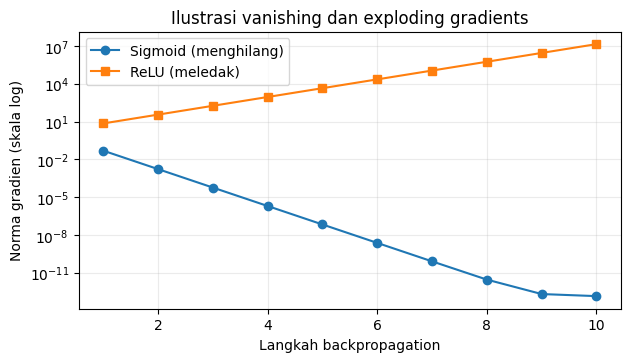

In [4]:
def sigmoid(x):
    x = np.clip(x, -40, 40)
    return 1.0 / (1.0 + np.exp(-x))

W_toy = np.array([[1., 4.], [4., 1.]])

def demonstrasi_gradien(aktivasi):
    state = np.array([1.0, 0.01])
    states = []
    for _ in range(10):
        z = state @ W_toy
        state = sigmoid(z) if aktivasi == 'sigmoid' else np.maximum(z, 0)
        states.append(state.copy())
    g = np.ones_like(state)
    norms = []
    for state in states[::-1]:
        deriv = state * (1 - state) if aktivasi == 'sigmoid' else (state > 0).astype(float)
        g = (g * deriv) @ W_toy.T
        norms.append(np.linalg.norm(g))
    return np.array(norms)

g_sig = demonstrasi_gradien('sigmoid')
g_relu = demonstrasi_gradien('relu')
print('Norma gradien sigmoid, awal→akhir backprop:', g_sig[0], '→', g_sig[-1])
print('Norma gradien ReLU, awal→akhir backprop  :', g_relu[0], '→', g_relu[-1])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(np.arange(1,11), g_sig, 'o-', label='Sigmoid (menghilang)')
ax.semilogy(np.arange(1,11), g_relu, 's-', label='ReLU (meledak)')
ax.set(xlabel='Langkah backpropagation', ylabel='Norma gradien (skala log)',
       title='Ilustrasi vanishing dan exploding gradients')
ax.legend(); ax.grid(alpha=0.25)
plt.show()
assert np.isfinite(g_sig).all() and np.isfinite(g_relu).all()

## 5. Gagasan *gated copy* pada LSTM 

Berbeda dari RNN biasa, LSTM mempertahankan dua keadaan: **hidden state** $h_t$ dan **cell state** $c_t$. *Cell state* diperbarui secara **aditif** dengan gerbang (*gates*):

$$\begin{aligned}
f_t &= \sigma(x_tW_{xf}+h_{t-1}W_{hf}+b_f) &&\text{(forget gate)}\\
i_t &= \sigma(x_tW_{xi}+h_{t-1}W_{hi}+b_i) &&\text{(input gate)}\\
o_t &= \sigma(x_tW_{xo}+h_{t-1}W_{ho}+b_o) &&\text{(output gate)}\\
g_t &= \tanh(x_tW_{xg}+h_{t-1}W_{hg}+b_g) &&\text{(candidate/update)}\\
c_t &= f_t\odot c_{t-1}+i_t\odot g_t\\
h_t &= o_t\odot\tanh(c_t).
\end{aligned}$$

- **Forget gate** $f_t$: bagian memori lama yang dipertahankan.
- **Input gate** $i_t$: berapa banyak kandidat memori baru yang ditulis.
- **Output gate** $o_t$: seberapa banyak informasi dari memori tampil dalam $h_t$.
- **Candidate** $g_t$ (di buku juga disebut $u$): isi informasi baru yang mungkin dimasukkan.

$\sigma$ adalah sigmoid pada rentang $(0,1)$, sementara $g_t$ berada pada $(-1,1)$. Jalur langsung $c_{t-1}\to c_t$ berturunan $f_t$ (jika gerbang dianggap tetap) sehingga dapat lebih mudah mempertahankan sinyal gradien jangka panjang dibanding transformasi berulang RNN. **LSTM mengurangi masalah, tetapi tidak menghilangkannya secara absolut.**

In [5]:
c_sebelum = np.array([[2., -1.]])
f_contoh = np.array([[0.9, 0.1]])
i_contoh = np.array([[0.2, 0.8]])
g_contoh = np.array([[0.5, 0.5]])
o_contoh = np.array([[0.7, 0.7]])
c_baru = f_contoh*c_sebelum + i_contoh*g_contoh
h_baru = o_contoh*np.tanh(c_baru)
print('Cell awal   :', c_sebelum)
print('Cell baru   :', c_baru)
print('Hidden baru :', h_baru)
print('Interpretasi: dimensi pertama banyak menyimpan memori lama,')
print('sementara dimensi kedua lebih banyak menerima update baru.')

Cell awal   : [[ 2. -1.]]
Cell baru   : [[1.9 0.3]]
Hidden baru : [[0.6694 0.2039]]
Interpretasi: dimensi pertama banyak menyimpan memori lama,
sementara dimensi kedua lebih banyak menerima update baru.


## 6. Implementasi NumPy: fungsi softmax, loss, dan penanganan gradien

Untuk menghindari kebutuhan mengimpor notebook sebelumnya, kelas LSTM di sini ditulis **secara mandiri**. Implementasi asli buku menggunakan `Tensor` dan operasi autograd Bab 13. Di notebook ini semua turunan operasi dituliskan manual; ini adalah **reproduksi mekanisme**, bukan penyalinan persis implementasi buku.

Untuk setiap blok sekuens dengan dimensi $(K,B)$, loss diambil sebagai rata-rata semua $K\times B$ prediksi karakter. Kode di bawah menggunakan *softmax* stabil secara numerik dan membatasi norma gradien global sebelum langkah SGD. *Clipping* adalah tambahan kestabilan eksperimen, bukan pengganti LSTM.

In [6]:
def softmax_stable(logits):
    z = logits - logits.max(axis=-1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=-1, keepdims=True)

def cross_entropy(probs, target):
    baris = np.arange(len(target))
    return -np.log(np.clip(probs[baris, target], 1e-12, 1)).mean()

def clip_and_update(params, grads, lr=0.12, max_norm=1.0):
    norm = float(np.sqrt(sum(np.sum(g*g) for g in grads.values())))
    factor = min(1.0, max_norm / (norm + 1e-12))
    for name in params:
        params[name] -= lr * factor * grads[name]
    return norm, factor

contoh_probs = softmax_stable(np.array([[1000., 999., 998.]]))
assert np.isclose(contoh_probs.sum(), 1.0)
assert np.isfinite(cross_entropy(contoh_probs, np.array([0])))
print('Softmax numerik stabil:', contoh_probs)

Softmax numerik stabil: [[0.6652 0.2447 0.09  ]]


## 7. Arsitektur pembanding: *vanilla RNN* dari Bab 13

RNN dipakai sebagai **pembanding** pada tugas dan partisi data yang sama. Pada kedua arsitektur, setiap karakter dipetakan ke embedding $E[x_t]$, lalu keluaran $h_t$ ditransformasikan menjadi *logits* di atas vocabulary:

$$\text{logits}_t=h_tW_y+b_y,\qquad p_t=\operatorname{softmax}(\text{logits}_t).$$

Kode berikut membuat RNN dengan turunan analitik untuk $\tanh$. Fungsi `backward` hanya menelusuri data pada blok saat ini; tidak ada graf lintas blok, jadi mekanisme TBPTT terlaksana secara eksplisit.

In [7]:
class VanillaRNN:
    def __init__(self, vocab_size, emb_dim=12, hidden_dim=24, seed=14):
        r = np.random.default_rng(seed)
        H, D, V = hidden_dim, emb_dim, vocab_size
        self.H = H
        self.p = {
            'E': r.normal(0, 0.24, (V, D)),
            'Wx': r.normal(0, 1/np.sqrt(D), (D, H)),
            'Wh': r.normal(0, 0.7/np.sqrt(H), (H, H)),
            'bh': np.zeros(H),
            'Wy': r.normal(0, 1/np.sqrt(H), (H, V)),
            'by': np.zeros(V),
        }

    def init_state(self, batch_size):
        return np.zeros((batch_size, self.H))

    def forward(self, X, state):
        caches, total = [], 0.
        h = state.copy()
        T, B = X.shape
        for t in range(T):
            ix = X[t]
            x = self.p['E'][ix]
            h_old = h
            h = np.tanh(x @ self.p['Wx'] + h_old @ self.p['Wh'] + self.p['bh'])
            probs = softmax_stable(h @ self.p['Wy'] + self.p['by'])
            caches.append((ix, x, h_old, h, probs))
        return caches, h.copy()

    def loss(self, caches, Y):
        return float(np.mean([cross_entropy(cache[-1], Y[t])
                              for t, cache in enumerate(caches)]))

    def backward(self, caches, Y):
        T, B = Y.shape
        grads = {k: np.zeros_like(v) for k, v in self.p.items()}
        dh_next = np.zeros((B, self.H))
        for t in reversed(range(T)):
            ix, x, h_old, h, probs = caches[t]
            dy = probs.copy()
            dy[np.arange(B), Y[t]] -= 1.0
            dy /= (B*T)
            grads['Wy'] += h.T @ dy
            grads['by'] += dy.sum(axis=0)
            dh = dy @ self.p['Wy'].T + dh_next
            dz = dh * (1 - h*h)
            grads['Wx'] += x.T @ dz
            grads['Wh'] += h_old.T @ dz
            grads['bh'] += dz.sum(axis=0)
            np.add.at(grads['E'], ix, dz @ self.p['Wx'].T)
            dh_next = dz @ self.p['Wh'].T
        return grads

    def next_prob(self, index, state):
        xs = np.array([[index]], dtype=np.int64)
        caches, state = self.forward(xs, state)
        return caches[-1][-1][0], state

rnn_toy = VanillaRNN(V)
cc, st = rnn_toy.forward(X_train[0], rnn_toy.init_state(BATCH_SIZE))
assert np.isfinite(rnn_toy.loss(cc, Y_train[0]))
print('RNN: loss contoh:', round(rnn_toy.loss(cc, Y_train[0]), 4))

RNN: loss contoh: 3.7348


## 8. Implementasi inti LSTM: empat gerbang dalam satu perkalian matriks

Agar efisien, empat proyeksi gerbang disatukan menjadi matriks $W_x\in\mathbb R^{D\times4H}$ dan $W_h\in\mathbb R^{H\times4H}$. Empat bagian hasil proyeksi kemudian dipisah menjadi $f,i,o,g$.

Cara ini **ekuivalen secara matematis** dengan penggunaan lapisan `xf`, `xi`, `xo`, `xc`, `hf`, `hi`, `ho`, `hc` yang ditulis di buku. Parameter keluaran memakai `Wy`, `by`. Pada kode ini forget-gate bias diawali 1 sebagai pilihan inisialisasi praktis, **bukan ketentuan buku**.

In [8]:
class LSTMManual:
    def __init__(self, vocab_size, emb_dim=12, hidden_dim=24, seed=15):
        r = np.random.default_rng(seed)
        H, D, V = hidden_dim, emb_dim, vocab_size
        self.H = H
        b = np.zeros(4*H)
        b[:H] = 1.0  # bias forget gate agar ingatan awal relatif dipertahankan
        self.p = {
            'E': r.normal(0, 0.24, (V, D)),
            'Wx': r.normal(0, 1/np.sqrt(D), (D, 4*H)),
            'Wh': r.normal(0, 0.65/np.sqrt(H), (H, 4*H)),
            'b': b,
            'Wy': r.normal(0, 1/np.sqrt(H), (H, V)),
            'by': np.zeros(V),
        }

    def init_state(self, batch_size):
        return (np.zeros((batch_size, self.H)),
                np.zeros((batch_size, self.H)))

    def forward(self, X, state):
        T, B = X.shape
        h, c = (state[0].copy(), state[1].copy())
        caches = []
        for t in range(T):
            ix = X[t]
            x = self.p['E'][ix]
            h_prev, c_prev = h, c
            z = x @ self.p['Wx'] + h_prev @ self.p['Wh'] + self.p['b']
            f, i, o = [sigmoid(q) for q in np.split(z[:, :3*self.H], 3, axis=1)]
            g = np.tanh(z[:, 3*self.H:])
            c = f*c_prev + i*g
            h = o*np.tanh(c)
            probs = softmax_stable(h @ self.p['Wy'] + self.p['by'])
            caches.append((ix, x, h_prev, c_prev, f, i, o, g, c, h, probs))
        return caches, (h.copy(), c.copy())

    def loss(self, caches, Y):
        return float(np.mean([cross_entropy(cache[-1], Y[t])
                              for t, cache in enumerate(caches)]))

    def backward(self, caches, Y):
        T, B = Y.shape
        H = self.H
        grads = {k: np.zeros_like(v) for k, v in self.p.items()}
        dh_next = np.zeros((B, H))
        dc_next = np.zeros((B, H))
        for t in reversed(range(T)):
            ix, x, h_prev, c_prev, f, i, o, g, c, h, probs = caches[t]
            dy = probs.copy()
            dy[np.arange(B), Y[t]] -= 1.0
            dy /= (B*T)
            grads['Wy'] += h.T @ dy
            grads['by'] += dy.sum(axis=0)
            dh = dy @ self.p['Wy'].T + dh_next
            tc = np.tanh(c)
            do = dh * tc
            dc = dh * o * (1 - tc*tc) + dc_next
            df = dc * c_prev
            di = dc * g
            dg = dc * i
            dc_next = dc * f
            dz = np.concatenate([df*f*(1-f), di*i*(1-i),
                                 do*o*(1-o), dg*(1-g*g)], axis=1)
            grads['Wx'] += x.T @ dz
            grads['Wh'] += h_prev.T @ dz
            grads['b'] += dz.sum(axis=0)
            np.add.at(grads['E'], ix, dz @ self.p['Wx'].T)
            dh_next = dz @ self.p['Wh'].T
        return grads

    def next_prob(self, index, state):
        xs = np.array([[index]], dtype=np.int64)
        caches, state = self.forward(xs, state)
        return caches[-1][-1][0], state

lstm_toy = LSTMManual(V)
cc, st = lstm_toy.forward(X_train[0], lstm_toy.init_state(BATCH_SIZE))
assert np.isfinite(lstm_toy.loss(cc, Y_train[0]))
assert st[0].shape == st[1].shape == (BATCH_SIZE, lstm_toy.H)
print('LSTM: loss contoh:', round(lstm_toy.loss(cc, Y_train[0]), 4))
print('Cell dan hidden shapes:', st[0].shape, st[1].shape)

LSTM: loss contoh: 3.6306
Cell dan hidden shapes: (8, 24) (8, 24)


## 9. Mengapa *backpropagation* LSTM bekerja?

Dengan $L$ menyatakan loss, turunan sel memori mencakup dua sumber: pengaruh $c_t$ pada keluaran $h_t$ dan pengaruhnya pada sel selanjutnya. Untuk satu langkah,

$$\frac{\partial L}{\partial c_t}=\underbrace{\frac{\partial L}{\partial h_t}\odot o_t\odot(1-\tanh^2(c_t))}_{\text{melalui hidden state}}+\underbrace{\frac{\partial L}{\partial c_{t+1}}\odot f_{t+1}}_{\text{melalui cell state}}.$$

Turunan menuju gerbang misalnya

$$\frac{\partial L}{\partial f_t}=\frac{\partial L}{\partial c_t}\odot c_{t-1},\quad
\frac{\partial L}{\partial i_t}=\frac{\partial L}{\partial c_t}\odot g_t,\quad
\frac{\partial L}{\partial g_t}=\frac{\partial L}{\partial c_t}\odot i_t.$$

Dalam kode `LSTMManual.backward`, gradien mengalir mundur melalui **dua jalur**: `dh_next` dan `dc_next`. Sementara itu `np.add.at` mengakumulasi gradien embedding untuk karakter yang mungkin muncul berkali-kali dalam satu potongan. Gradient checking berikut membandingkan turunan analitik dengan *finite differences*; ini jauh lebih kuat daripada hanya mengamati loss menurun.

In [9]:
# Model sangat kecil untuk uji turunan numerik
m_check = LSTMManual(vocab_size=6, emb_dim=3, hidden_dim=3, seed=19)
X_check = np.array([[0, 1], [2, 1], [3, 4]], dtype=np.int64)
Y_check = np.array([[1, 2], [1, 0], [2, 3]], dtype=np.int64)
state_check = m_check.init_state(batch_size=2)
cache_check, _ = m_check.forward(X_check, state_check)
grad_check = m_check.backward(cache_check, Y_check)

def numerik_deriv(model, param, indeks, eps=1e-5):
    data = model.p[param]
    asal = data[indeks]
    data[indeks] = asal + eps
    plus = model.loss(model.forward(X_check, state_check)[0], Y_check)
    data[indeks] = asal - eps
    minus = model.loss(model.forward(X_check, state_check)[0], Y_check)
    data[indeks] = asal
    return (plus - minus) / (2*eps)

check_entries = [('E', (1,0)), ('Wx', (1,2)), ('Wh', (0,6)),
                 ('b', (1,)), ('Wy', (2,3)), ('by',(2,))]
for nama, idx in check_entries:
    g_analitik = grad_check[nama][idx]
    g_numerik = numerik_deriv(m_check, nama, idx)
    galat = abs(g_analitik - g_numerik)
    print(f'{nama:>2}{str(idx):>8} analitik={g_analitik:+.8f}, '
          f'numerik={g_numerik:+.8f}, selisih={galat:.2e}')
    assert galat < 2e-5, f'Gradient checking gagal: {nama}{idx}'
print('Gradient checking LSTM: LULUS')

 E  (1, 0) analitik=-0.04799433, numerik=-0.04799433, selisih=1.69e-11
Wx  (1, 2) analitik=+0.00009383, numerik=+0.00009383, selisih=7.79e-12
Wh  (0, 6) analitik=-0.00074121, numerik=-0.00074121, selisih=1.46e-11
 b    (1,) analitik=+0.00046732, numerik=+0.00046732, selisih=4.52e-12
Wy  (2, 3) analitik=+0.00608222, numerik=+0.00608222, selisih=6.28e-12
by    (2,) analitik=-0.16622228, numerik=-0.16622228, selisih=1.10e-12
Gradient checking LSTM: LULUS


## 10. Pelatihan TBPTT dan *state carry-over*

Setiap *epoch* dimulai dengan kondisi awal nol. Dalam epoch, $(h_t,c_t)$ diteruskan dari satu potongan ke potongan berikutnya. Karena implementasi memakai array NumPy dan menghitung graf turunan hanya dari cache **potongan saat ini**, batas TBPTT otomatis memutus gradien masa lalu meskipun nilainya tetap dibawa.

**Tidak** dilakukan pengacakan urutan potongan, sebab kondisi tersembunyi dari batch sebelumnya hanya koheren jika potongan sekuens tetap berurutan. Setiap langkah melibatkan seluruh token pada segmen (`loss` dirata-ratakan untuk `T × B`).

In [10]:
def evaluate_model(model, X, Y):
    state = model.init_state(X.shape[2])
    total_loss, total_correct, n_total = 0., 0, 0
    for xs, ys in zip(X, Y):
        cache, state = model.forward(xs, state)
        B, T = xs.shape[1], xs.shape[0]
        n = B*T
        total_loss += model.loss(cache, ys)*n
        pred = np.stack([item[-1].argmax(axis=1) for item in cache])
        total_correct += int(np.sum(pred == ys))
        n_total += n
    return {'nll': total_loss/n_total,
            'ppl': float(np.exp(total_loss/n_total)),
            'accuracy': total_correct/n_total}

def train_model(model, epochs, lr=0.25, max_norm=1.0):
    hist = []
    for epoch in range(1, epochs+1):
        state = model.init_state(BATCH_SIZE)
        grad_norm = []
        for xs, ys in zip(X_train, Y_train):
            cache, state = model.forward(xs, state)
            grads = model.backward(cache, ys)
            norm, _ = clip_and_update(model.p, grads, lr=lr, max_norm=max_norm)
            grad_norm.append(norm)
        tr = evaluate_model(model, X_train, Y_train)
        va = evaluate_model(model, X_val, Y_val)
        hist.append({'epoch': epoch, 'train_nll': tr['nll'],
                     'val_nll': va['nll'], 'val_ppl': va['ppl'],
                     'val_acc': va['accuracy'],
                     'mean_grad_norm_preclip': np.mean(grad_norm)})
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f'Epoch {epoch:02d} | NLL latih {tr["nll"]:.3f} | '
                  f'NLL validasi {va["nll"]:.3f} | '
                  f'PPL validasi {va["ppl"]:.2f} | '
                  f'Acc validasi {va["accuracy"]:.1%}')
    return hist

EPOCHS = 30  # kurangi atau tambah dengan mempertimbangkan daya komputasi
rnn = VanillaRNN(V, emb_dim=12, hidden_dim=24, seed=SEED)
lstm = LSTMManual(V, emb_dim=12, hidden_dim=24, seed=SEED + 1)
print('Training vanilla RNN')
history_rnn = train_model(rnn, epochs=EPOCHS, lr=0.22)
print('\nTraining LSTM')
history_lstm = train_model(lstm, epochs=EPOCHS, lr=0.22)

Training vanilla RNN
Epoch 01 | NLL latih 3.080 | NLL validasi 3.062 | PPL validasi 21.38 | Acc validasi 20.8%


Epoch 05 | NLL latih 2.232 | NLL validasi 2.215 | PPL validasi 9.16 | Acc validasi 37.8%


Epoch 10 | NLL latih 1.779 | NLL validasi 1.782 | PPL validasi 5.94 | Acc validasi 46.6%


Epoch 15 | NLL latih 1.503 | NLL validasi 1.524 | PPL validasi 4.59 | Acc validasi 55.8%


Epoch 20 | NLL latih 1.270 | NLL validasi 1.307 | PPL validasi 3.69 | Acc validasi 60.9%


...

Epoch 10 | NLL latih 2.772 | NLL validasi 2.763 | PPL validasi 15.84 | Acc validasi 26.1%


Epoch 15 | NLL latih 2.429 | NLL validasi 2.415 | PPL validasi 11.19 | Acc validasi 31.2%


Epoch 20 | NLL latih 2.145 | NLL validasi 2.131 | PPL validasi 8.42 | Acc validasi 38.0%


Epoch 25 | NLL latih 1.951 | NLL validasi 1.946 | PPL validasi 7.00 | Acc validasi 41.4%


Epoch 30 | NLL latih 1.820 | NLL validasi 1.825 | PPL validasi 6.20 | Acc validasi 43.6%


## 11. Mengevaluasi hasil secara kuantitatif

Metrik utama:

- **NLL (nats per karakter):** $-\frac{1}{N}\sum_n\log P_\theta(y_n\mid \text{konteks}_n)$; semakin kecil semakin baik.
- **Perplexity:** $\exp(\mathrm{NLL})$; semakin kecil semakin baik, dengan definisi vocabulary dan preprocessing yang sama.
- **Accuracy karakter:** proporsi posisi yang prediksi *argmax*-nya tepat. Nilai ini dapat mendukung evaluasi, namun mudah menyesatkan bila karakter seperti spasi muncul sangat sering.

Baseline sederhana adalah **model unigram** yang mengabaikan konteks, dengan peluang karakter dihitung dari frekuensi data latih. RNN/LSTM dapat dibandingkan dengannya, tetapi metrik pada korpus sintetis **tidak mengukur kemampuan menulis Shakespeare**.

In [11]:
frekuensi = np.bincount(train_ids, minlength=V).astype(float) + 0.5
p_unigram = frekuensi / frekuensi.sum()
y_val_flat = Y_val.ravel()
ce_unigram = float(-np.log(p_unigram[y_val_flat]).mean())
acc_unigram = float(np.mean(y_val_flat == np.argmax(p_unigram)))
metrics_rnn = evaluate_model(rnn, X_val, Y_val)
metrics_lstm = evaluate_model(lstm, X_val, Y_val)
print('Perbandingan data validasi pada korpus:', SUMBER_DATA)
print(f'{"Metode":<17} {"NLL":>8} {"Perplexity":>12} {"Accuracy":>11}')
print('-' * 54)
for name, nll, ppl, acc in [
    ('Unigram', ce_unigram, np.exp(ce_unigram), acc_unigram),
    ('Vanilla RNN', metrics_rnn['nll'], metrics_rnn['ppl'], metrics_rnn['accuracy']),
    ('LSTM', metrics_lstm['nll'], metrics_lstm['ppl'], metrics_lstm['accuracy'])
]:
    print(f'{name:<17} {nll:>8.3f} {ppl:>12.3f} {acc:>10.1%}')

Perbandingan data validasi pada korpus: Korpus dialog sintetis berulang (bukan Shakespeare)
Metode                 NLL   Perplexity    Accuracy
------------------------------------------------------
Unigram              3.086       21.891      16.2%
Vanilla RNN          0.995        2.706      69.4%
LSTM                 1.825        6.203      43.6%


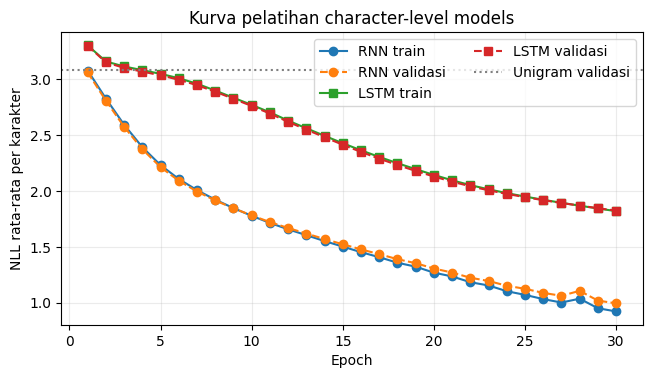

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
epoch_axis = np.arange(1, EPOCHS+1)
ax.plot(epoch_axis, [x['train_nll'] for x in history_rnn], 'o-', label='RNN train')
ax.plot(epoch_axis, [x['val_nll'] for x in history_rnn], 'o--', label='RNN validasi')
ax.plot(epoch_axis, [x['train_nll'] for x in history_lstm], 's-', label='LSTM train')
ax.plot(epoch_axis, [x['val_nll'] for x in history_lstm], 's--', label='LSTM validasi')
ax.axhline(ce_unigram, ls=':', color='gray', label='Unigram validasi')
ax.set(xlabel='Epoch', ylabel='NLL rata-rata per karakter',
       title='Kurva pelatihan character-level models')
ax.grid(alpha=0.25); ax.legend(ncol=2)
plt.show()

## 12. *Text generation* dan pengaruh *temperature* (hlm. 271, 279)

Setelah mempelajari distribusi karakter berikutnya, model dapat menghasilkan teks satu karakter demi satu. Berikan karakter awal (*prompt*) dan ulangi:

1. Hitung $p_t=\mathrm{softmax}(\text{logits}_t/\tau)$.
2. Pilih indeks karakter mengikuti distribusi $p_t$.
3. Gunakan karakter terpilih sebagai input pada timestep berikutnya.

**Temperature** $\tau$ kecil membuat probabilitas lebih tajam dan prediksi lebih deterministik; $\tau$ besar membuat sampel lebih beragam. Algoritme ini menggantikan trik pemilihan sampel pada contoh buku dengan `numpy.random.choice` yang secara eksplisit mengambil sampel kategoris sesuai distribusi.

Teks yang tercipta pada demo kemungkinan meniru pola dialog yang berulang. **Jangan menganggap hasilnya setara dengan penguasaan bahasa sastra.**

In [13]:
def sample_text(model, prompt, n_char=160, temperature=0.8, seed=100):
    if temperature <= 0:
        raise ValueError('temperature harus positif')
    r = np.random.default_rng(seed)
    state = model.init_state(1)
    unseen = [c for c in prompt if c not in char2idx]
    if unseen:
        raise ValueError(f'Karakter prompt tidak dikenal: {unseen}')
    for ch in prompt[:-1]:
        _, state = model.next_prob(char2idx[ch], state)
    index = char2idx[prompt[-1]]
    generated = prompt
    for _ in range(n_char):
        probs, state = model.next_prob(index, state)
        logits = np.log(np.clip(probs, 1e-12, 1))/temperature
        temp_p = softmax_stable(logits)
        index = int(r.choice(len(temp_p), p=temp_p))
        generated += idx2char[index]
    return generated

AWAL = 'R' if 'R' in char2idx else idx2char[int(indices[0])]
print('SAMPEL LSTM (temperature=0.7)')
print(sample_text(lstm, AWAL, n_char=260, temperature=0.7, seed=78))
print('\nSAMPEL LSTM (temperature=1.3)')
print(sample_text(lstm, AWAL, n_char=260, temperature=1.3, seed=78))

SAMPEL LSTM (temperature=0.7)
Ratan laman dapa tanng kengka slesbbetang maki tanga kemam tanpar man barih ap mamar atar ira.
RUUA: banga ink mejegak bang melaka kengi jang tirai.
RAAc swkegan ibapa un imguu ira.
UAJNA: upan kemeia ing ing etian atari tata.A.AJ :anan igan pang keniraw inga l

SAMPEL LSTM (temperature=1.3)
Ratboak georPhap tamuT lbemtahor talim lbara tiu
JEUAGN: dasanuki melae.kjA.
R aRPUu Nsboalid imuo .J:.ANA: rmapa.f bak emaniR i.R
PPJUS akan topeksang ybizur jeha.mca yi iinyyi.aNPNs: tecuuni kalam hajga iog gmkana
oAhsANUS Gsanm?.garr ilan pim Tinltuaya.PPRAJ


## 13. Memeriksa gerbang dan retensi memori secara empiris

Jalur langsung cell $\partial c_t / \partial c_{t-1}=f_t$ (dengan menganggap nilai gerbang tidak berubah) menjelaskan keuntungan LSTM untuk mempertahankan informasi. Jika $f=0.99$ sepanjang 50 langkah, komponen gradien langsung menjadi $0.99^{50}$; jika $f=0.1$, nilai yang sama menjadi $0.1^{50}$.

Namun ingatan tidak otomatis sempurna: parameter gerbang dipelajari dari data dan BPTT terbatas tetap menghambat sinyal pelatihan jangka sangat panjang. Berikut perbandingan deterministik terhadap jalur retensi langsung.

In [14]:
k = 50
for gate in [0.1, 0.5, 0.9, 0.99, 1.0]:
    print(f'Forget gate={gate:>4}: retensi jalur langsung setelah {k} langkah = {gate**k:.3e}')

# Cek gerbang hasil forward pada 1 minibatch.
cache_lstm, _ = lstm.forward(X_val[0], lstm.init_state(BATCH_SIZE))
f_pertama = cache_lstm[0][4]  # cache: ix, x, h_prev, c_prev, f, ...
i_pertama = cache_lstm[0][5]
o_pertama = cache_lstm[0][6]
for nama, arr in [('forget', f_pertama), ('input', i_pertama), ('output', o_pertama)]:
    print(f'{nama:>7} gate: min={arr.min():.3f}, mean={arr.mean():.3f}, max={arr.max():.3f}')
    assert np.all((arr > 0) & (arr < 1))

Forget gate= 0.1: retensi jalur langsung setelah 50 langkah = 1.000e-50
Forget gate= 0.5: retensi jalur langsung setelah 50 langkah = 8.882e-16
Forget gate= 0.9: retensi jalur langsung setelah 50 langkah = 5.154e-03
Forget gate=0.99: retensi jalur langsung setelah 50 langkah = 6.050e-01
Forget gate= 1.0: retensi jalur langsung setelah 50 langkah = 1.000e+00
 forget gate: min=0.294, mean=0.724, max=0.937
  input gate: min=0.206, mean=0.599, max=0.944
 output gate: min=0.025, mean=0.576, max=0.958


## 14. *Ablation* sederhana: mengganti panjang TBPTT tanpa mengarang hasil

Panjang $K$ adalah hiperparameter. $K$ lebih besar memperluas rentang gradien, tetapi memperbesar biaya komputasi dan potensi kesulitan numerik. Panjang lebih pendek efisien, tetapi mengurangi kemampuan model mempelajari dependensi yang membutuhkan atribusi gradien lintas jarak jauh.

Sel berikut **menunjukkan bentuk batch dan jumlah langkah**, bukan mengklaim pengaruh metrik yang belum diuji ulang dengan model terlatih dan kontrol hiperparameter identik. Untuk eksperimen kausal yang lebih kuat, latih ulang model dari seed yang sama pada beberapa nilai $K$, dengan anggaran pembaruan sebanding dan beberapa replikasi.

In [15]:
for panjang in (8, 16, 20, 32):
    x_demo, y_demo = make_tbptt_batches(train_ids, BATCH_SIZE, panjang)
    print(f'BPTT={panjang:>2}: {x_demo.shape[0]:>3} potongan x '
          f'{x_demo.shape[1]} timestep x {x_demo.shape[2]} sampel')

BPTT= 8:  58 potongan x 8 timestep x 8 sampel
BPTT=16:  29 potongan x 16 timestep x 8 sampel
BPTT=20:  23 potongan x 20 timestep x 8 sampel
BPTT=32:  14 potongan x 32 timestep x 8 sampel


## 15. Panduan reproduksi lebih dekat dengan eksperimen buku

Untuk mengganti demo dengan korpus asli:

1. Letakkan berkas teks Shakespeare bernama `shakespear.txt` di folder notebook (buku menggunakan ejaan tersebut). Pastikan hak akses/penggunaan data sesuai ketentuan sumber.
2. Ubah `USE_SHAKESPEARE_FILE = True` di sel pembacaan data dan jalankan semua sel dari awal.
3. Buku memilih **embedding=512**, **hidden=512**, **batch_size=16**, **bptt=25**, dan pembaruan *learning rate* awal **0.05**; replikasi ukuran ini membutuhkan komputasi jauh lebih besar (hlm. 277–279).
4. Untuk mendekati reproduksi implementasi, gunakan kelas `Tensor`, `Embedding`, `Linear`, `CrossEntropyLoss`, dan `SGD` dari Bab 13 serta `LSTMCell` yang didefinisikan di Bab 14, kemudian latih pada berkas asli.
5. Rekam versi dependensi, perangkat keras, seed, waktu pelatihan, kurva NLL/perplexity, pemisahan data, sampel teks dan variasi antar-replikasi.

**Catatan kesesuaian:** Dalam buku, model awal didasarkan pada *vanilla RNN* lalu arsitekturnya diganti dengan LSTM. Selama pergantian itu, setiap timestep LSTM memakai **dua state** `(h, c)` dan harus memutus **keduanya** pada batas TBPTT (hlm. 278). Implementasi NumPy ini melakukan hal yang sama secara numerik, tanpa menyimpan graf lintas potongan.

## 16. Analisis kritis dan keterbatasan eksperimen

| Komponen | Isi buku | Implementasi notebook | Implikasi |
|---|---|---|---|
| Data | `shakespear.txt` | Korpus dialog sintetis default; opsi `shakespear.txt` | Tidak dapat menyatakan reproduksi kualitas teks Shakespeare tanpa data asli |
| Arsitektur | RNN lalu LSTM berkomponen `Linear` | RNN dan LSTM NumPy eksplisit | Persamaan inti sama, tetapi kode dan pilihan inisialisasi berbeda |
| Autograd | Framework dari Bab 13 | Gradien manual dengan *gradient checking* | Menunjukkan pemahaman turunan; bukan salinan framework |
| Optimizer | SGD dan penurunan alpha per epoch | SGD + *gradient clipping*, alpha tetap | Kecepatan konvergensi tidak identik |
| Ukuran model | Hidden/embedding 512 | Default hidden 24 dan embedding 12 | Lebih cepat, kapasitas jauh lebih kecil |
| Evaluasi | Loss dan teks sampel; pelatihan panjang | NLL, perplexity, akurasi, unigram baseline dan sampel | Tambahan pemeriksaan; angka tidak dibandingkan langsung dengan buku |

**Ancaman validitas:** Data demonstrasi berulang; validasi memiliki pola sejenis dengan pelatihan, sehingga metrik validasi dapat optimistis. Model LSTM juga tidak selalu pasti mengungguli RNN pada korpus kecil, jumlah epoch sedikit, dan pemilihan hiperparameter tertentu. Satu seed serta satu pemisahan data tidak cukup untuk menyimpulkan keunggulan arsitektur secara umum. Untuk kesimpulan kuat dibutuhkan banyak seed, data uji tak terlihat, kontrol parameter/biaya komputasi, dan *confidence interval*.

**Kepercayaan:** tinggi untuk turunan dan mekanisme dasar (divalidasi oleh finite differences); sedang untuk demonstrasi bahwa kedua model dapat belajar pola lokal sederhana; rendah untuk klaim tentang kualitas generasi Shakespeare atau dominasi LSTM tanpa eksperimen pada korpus aslinya.

## 17. Rangkuman Chapter 14

1. **Character-level language modeling:** prediksi karakter berikutnya berdasarkan konteks yang telah dilihat, bukan prediksi kata utuh.
2. **Truncated BPTT:** mempertahankan urutan dan meneruskan nilai state antarblok, tetapi mengakhiri aliran gradien setiap `bptt` timestep agar pelatihan lebih efisien.
3. **Vanishing/exploding gradients:** muncul akibat perkalian turunan dan matriks berulang ketika gradien melalui banyak timestep. Analogi sigmoid/ReLU pada hlm. 273 mendemonstrasikan kedua ekstrem.
4. **LSTM:** menyimpan *cell state* yang dapat disalin atau dimodifikasi secara aditif melalui *forget*, *input*, dan *output gates* serta nilai kandidat $g$.
5. **Pelatihan dan generasi:** LSTM dapat digunakan dalam pipeline embedding → cell → logits → cross-entropy; hasil dipakai untuk menghasilkan karakter satu per satu. Nilai temperature mengontrol variasi sampel.
6. **Integritas hasil:** notebook ini adalah reproduksi **algoritme dan gagasan** Bab 14. Reproduksi penuh hasil numerik memerlukan korpus asli, arsitektur/setelan buku, serta anggaran komputasi sebanding.